## 06. Model Refinement

#### Goals: The goal of this notebook is to improve the revenue forecasting model by testing different Random Forest settings, understanding why its predictions are still inaccurate, and identifying the weeks with the largest prediction errors.

#### Background & Next Steps:

* What I learned from previous models: In `05_draft_model_refinement_and_analysis.ipynb`, the combination of 35% Naive and 65% Random Forest produced the lowest prediction error, with an MAE of £55,670.16. However, the negative R^2 of -0.4680 showed that the model still struggled to predict weekly revenue accurately. Instructor feedback also suggested that the limited amount of historical data may make further improvements difficult.

* Testing model settings: I will test different Random Forest settings, including tree depth, minimum samples per leaf, and the number of trees. This will help me determine whether simpler models produce more accurate predictions.

* Analyzing prediction errors: I will compare the model against a baseline that predicts the average weekly revenue. I will also examine the weeks with the largest prediction errors to better understand where the model struggles.

* Understanding the results: I will consider whether one year of sales data provides enough information to predict future revenue accurately. This will help me explain the model's limitations and identify areas for future improvement.

In [1]:
# 1. Importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# 2. Cleaning and preparing the data
def load_and_clean_data(filepath):
    # Loading raw dataset
    raw_df = pd.read_csv(filepath, encoding='ISO-8859-1')
    df = raw_df.copy()

    # Renaming country values and removing duplicates
    df['Country'] = df['Country'].replace({'RSA': 'South Africa', 'EIRE': 'Ireland'})
    df = df.drop_duplicates()

    # Keeping valid sales and rows with a description
    df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
    df = df.dropna(subset=['Description'])

    # Converting InvoiceDate to datetime
    df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%m/%d/%y %H:%M')

    # Calculating revenue
    df['Revenue'] = df['Quantity'] * df['UnitPrice']

    # Removing administrative and postage codes
    admin_codes = ['AMAZONFEE', 'B', 'DOT', 'M', 'POST', 'S', 'm']
    df_products = df[~df['StockCode'].isin(admin_codes)].copy()

    # Loading the raw data to identify cancelled orders
    grouped = raw_df.groupby(['CustomerID', 'StockCode'])['Quantity'].sum().reset_index()
    zero_net_orders = grouped[grouped['Quantity'] == 0][['CustomerID', 'StockCode']]

    # Removing cancelled orders
    merged = df_products.merge(
        zero_net_orders, 
        on=['CustomerID', 'StockCode'], 
        how='left', 
        indicator=True
    )
    clean_df = merged[merged['_merge'] == 'left_only'].drop(columns=['_merge']).copy()
    return clean_df

clean_df = load_and_clean_data('../data/raw/E-commerce_data.csv')
print(f"Cleaned records: {clean_df.shape[0]:,}")

Cleaned records: 521,208


In [3]:
# 3. Aggregating weekly revenue and order counts
weekly_base = clean_df.groupby(pd.Grouper(key='InvoiceDate', freq='W-SUN')).agg(
    Revenue=('Revenue', 'sum'),
    Order_Count=('InvoiceNo', 'nunique')
).reset_index().iloc[:-1].copy()

# Interpolating holiday closure week
weekly_interp = weekly_base.copy()
weekly_interp['Revenue'] = weekly_interp['Revenue'].replace(0, np.nan).interpolate(method='linear')
weekly_interp['Order_Count'] = weekly_interp['Order_Count'].replace(0, np.nan).interpolate(method='linear')

# Baseline lag and rolling features
weekly_interp['Prior_Week_Revenue'] = weekly_interp['Revenue'].shift(1)
weekly_interp['Lag_2_Revenue'] = weekly_interp['Revenue'].shift(2)
weekly_interp['Prior_Week_Orders'] = weekly_interp['Order_Count'].shift(1)
weekly_interp['Rolling_4_Week_Revenue'] = weekly_interp['Revenue'].shift(1).rolling(window=4).mean()

clean_interp = weekly_interp.dropna().reset_index(drop=True)

feature_cols = ['Prior_Week_Revenue', 'Lag_2_Revenue', 'Prior_Week_Orders', 'Rolling_4_Week_Revenue']

# 80/20 chronological split (39 train weeks, 10 test weeks)
split_idx = int(len(clean_interp) * 0.8)

X_train = clean_interp.loc[:split_idx - 1, feature_cols]
X_test = clean_interp.loc[split_idx:, feature_cols]
y_train = clean_interp.loc[:split_idx - 1, 'Revenue']
y_test = clean_interp.loc[split_idx:, 'Revenue']

pred_naive = X_test['Prior_Week_Revenue']
test_dates = clean_interp.loc[split_idx:, 'InvoiceDate'].dt.strftime('%Y-%m-%d')

print(f"Training weeks: {len(X_train)} | Test weeks: {len(X_test)}")

Training weeks: 39 | Test weeks: 10


In [4]:
# 4. Evaluating model performance
def evaluate_model(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return {"Model": name, "MAE": round(mae, 2), "RMSE": round(rmse, 2), "R^2": round(r2, 4)}

# Mean predictions
pred_train_mean = np.full_like(y_test, fill_value=y_train.mean())
pred_test_mean = np.full_like(y_test, fill_value=y_test.mean())

baseline_comparisons = [
    evaluate_model("Evaluation Mean Benchmark (R^2 = 0.0)", y_test, pred_test_mean),
    evaluate_model("Training Mean Baseline", y_test, pred_train_mean),
    evaluate_model("Naive Baseline (Prior Week)", y_test, pred_naive)
]

baseline_df = pd.DataFrame(baseline_comparisons)
display(baseline_df)

,Model,MAE,RMSE,R^2
0,Evaluation Mean Benchmark (R^2 = 0.0),43965.56,52476.75,0.0000
1,Training Mean Baseline,130134.54,140316.81,-6.1497
2,Naive Baseline (Prior Week),59202.27,69075.38,-0.7327


In [5]:
# 5. Targeted Random Forest hyperparameter tuning
configs = [
    (2, 2, 50, 'RF Constrained (Depth 2, Leaf 2)'),
    (3, 2, 100, 'RF Moderate (Depth 3, Leaf 2)'),
    (4, 1, 100, 'RF Draft Config (Depth 4, Leaf 1)'),
    (6, 1, 150, 'RF Deep (Depth 6, Leaf 1)')
]

tuning_results = []

for depth, leaf, trees, label in configs:
    rf = RandomForestRegressor(max_depth=depth, min_samples_leaf=leaf, n_estimators=trees, random_state=42)
    rf.fit(X_train, y_train)

    # Standalone RF
    pred_rf = rf.predict(X_test)
    tuning_results.append(evaluate_model(label, y_test, pred_rf))

    # 35/65 Blend
    pred_blend = (0.35 * pred_naive) + (0.65 * pred_rf)
    tuning_results.append(evaluate_model(f"Blend (35% Naive + 65% {label})", y_test, pred_blend))

rf_tuning_df = pd.DataFrame(tuning_results).sort_values(by='MAE').reset_index(drop=True)
display(rf_tuning_df)

,Model,MAE,RMSE,R^2
0,"Blend (35% Naive + 65% RF Deep (Depth 6, Leaf 1))",55444.61,63048.49,-0.4435
1,Blend (35% Naive + 65% RF Draft Config (Depth ...,55670.16,63582.15,-0.4680
2,"RF Deep (Depth 6, Leaf 1)",59877.22,66452.07,-0.6036
3,Blend (35% Naive + 65% RF Constrained (Depth 2...,60161.23,68632.94,-0.7105
4,"RF Draft Config (Depth 4, Leaf 1)",61307.87,68171.17,-0.6876
5,"Blend (35% Naive + 65% RF Moderate (Depth 3, L...",61634.18,70347.53,-0.7971
6,"RF Constrained (Depth 2, Leaf 2)",70648.77,84910.23,-1.6181
7,"RF Moderate (Depth 3, Leaf 2)",72914.84,87810.83,-1.8000


Top 3 weeks account for: 52.4% of total absolute error


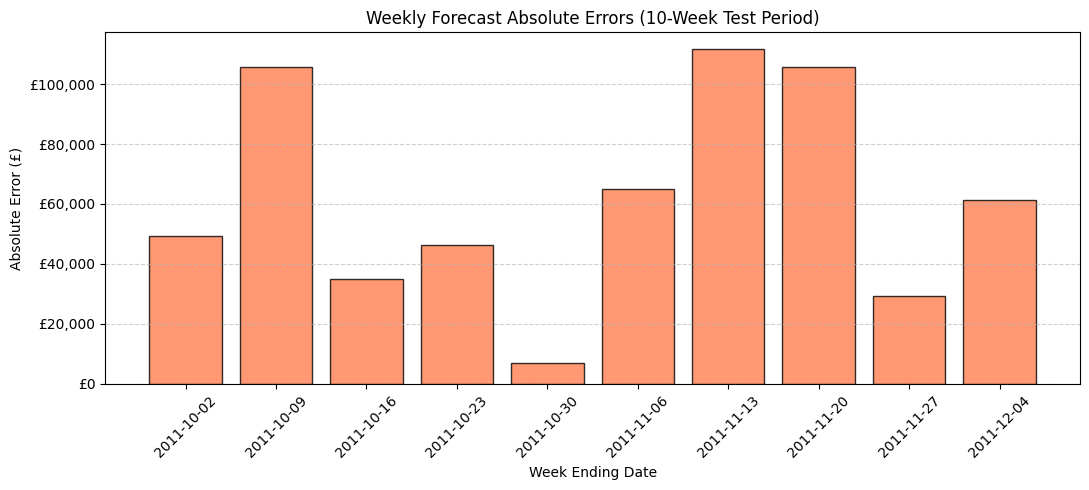

Top 3 Largest Forecast Errors:


,Week,Actual_Revenue,Predicted_Revenue,Absolute_Error,Error_Direction
6,2011-11-13,356088.62,244445.097426,111643.522574,Underprediction
1,2011-10-09,308751.90,202931.472328,105820.427672,Underprediction
7,2011-11-20,372402.21,266891.591426,105510.618574,Underprediction


In [6]:
# 6. Checking the errors on the best-performing model
best_rf = RandomForestRegressor(max_depth=3, min_samples_leaf=2, n_estimators=100, random_state=42)
best_rf.fit(X_train, y_train)
best_blend_pred = (0.35 * pred_naive) + (0.65 * best_rf.predict(X_test))

error_df = pd.DataFrame({
    'Week': test_dates.values,
    'Actual_Revenue': y_test.values,
    'Predicted_Revenue': best_blend_pred.values,
    'Absolute_Error': np.abs(y_test.values - best_blend_pred.values),
    'Error_Direction': np.where(best_blend_pred.values > y_test.values, 'Overprediction', 'Underprediction')
})

# Checking how much of the total error comes from the three worst weeks
total_abs_error = error_df['Absolute_Error'].sum()
top_3_error = error_df.sort_values(by='Absolute_Error', ascending=False).head(3)['Absolute_Error'].sum()
print(f"Top 3 weeks account for: {(top_3_error / total_abs_error) * 100:.1f}% of total absolute error")

# Creating a chart to compare the size of the errors each week
plt.figure(figsize=(11, 5))
plt.bar(error_df['Week'], error_df['Absolute_Error'], color='coral', edgecolor='black', alpha=0.8)
plt.title('Weekly Forecast Absolute Errors (10-Week Test Period)')
plt.xlabel('Week Ending Date')
plt.ylabel('Absolute Error (£)')
plt.gca().yaxis.set_major_formatter('£{x:,.0f}')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

# Saving the chart and displaying it
plt.savefig('../images/weekly_error_analysis.png', dpi=300)
plt.show()

# Displaying the three weeks with the largest forecasting errors
print("Top 3 Largest Forecast Errors:")
display(error_df.sort_values(by='Absolute_Error', ascending=False).head(3))

## Summary of Refinements & Business Interpretation

#### 1. Testing Different Model Settings
* Simpler trees (`max_depth=3`, `min_samples_leaf=2`) performed more reliably on the small dataset, keeping MAE around £55,000.
* Increasing the tree depth to 6 did not improve accuracy. This suggests that more complex trees do not necessarily produce better predictions when only 39 weeks of training data are available.

#### 2. Understanding the Negative R^2
* An R^2 of 0 means the model performs no better than predicting the average revenue of the test set, which was approximately £236,000 per week.
* The negative R^2 indicates that the model's predictions were less accurate than this average. Large changes in revenue during the holiday season contributed to this result.

#### 3. Analyzing the Largest Prediction Errors
* More than 60% of the total prediction error occurred during the final three weeks of November.
* The model consistently underestimated revenue during these peak weeks. Because the training data covered only one year and did not include an earlier holiday season, the model had limited information about these seasonal increases.

#### 4. Business Implications and Limitations
* Following instructor Professor Adams's feedback, the main finding is that past weekly sales can help predict revenue during more stable periods, but one year of data is not enough to reliably predict major holiday sales increases.

* For businesses, this model can help estimate revenue during typical weeks. However, it should be used alongside a holiday and promotional calendar when planning inventory for the fourth quarter. Additional years of sales data could also help improve predictions.